In [113]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

In [114]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [115]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

<AxesSubplot:title={'center':'vix ln return'}>

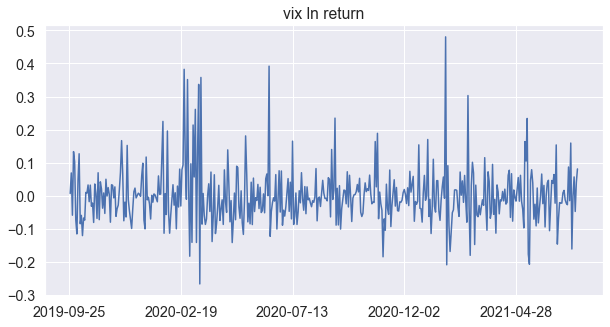

In [116]:
df["vix_ln_return"].plot(figsize=(10, 5),title='vix ln return')

<AxesSubplot:title={'center':'vix ln return'}>

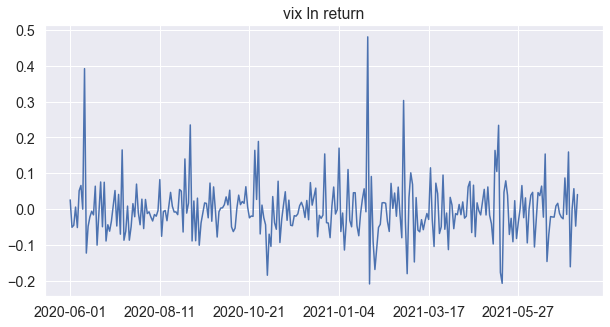

In [117]:
df_part3["vix_ln_return"].plot(figsize=(10, 5),title='vix ln return')

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


<AxesSubplot:xlabel='vix_ln_return', ylabel='sentiment'>

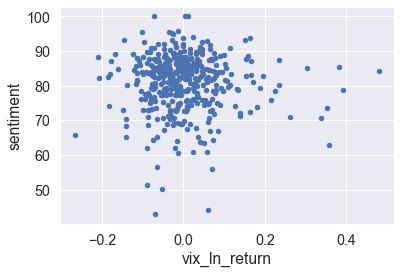

In [118]:
df.plot(x="vix_ln_return", y="sentiment", kind="scatter")

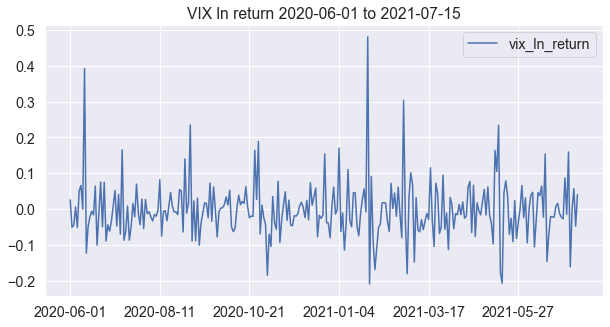

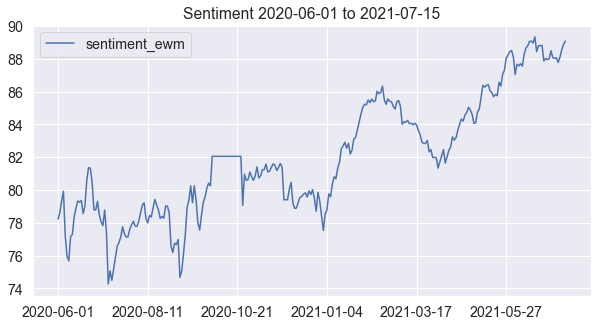

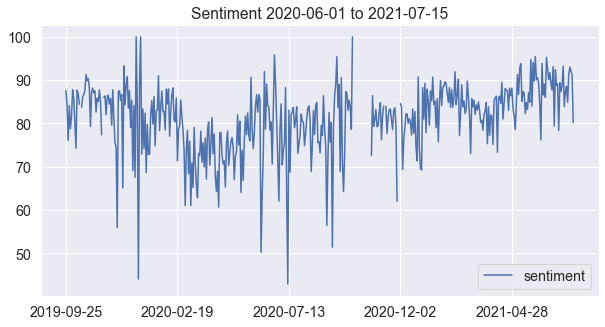

In [119]:
dfplot = df_part3[['vix_ln_return']].plot(figsize=(10, 5),title='VIX ln return 2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/vix_ln_return.png")

fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentiment.png")
df_part3[['sentiment_ewm']].plot(figsize=(10, 5),title='Sentiment 2020-06-01 to 2021-07-15')
fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentiment_ewm.png")
dfplot = df[['sentiment']].plot(figsize=(10, 5),title='Sentiment 2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()

In [120]:
df_part3.index

Index(['2020-06-01', '2020-06-02', '2020-06-03', '2020-06-04', '2020-06-05',
       '2020-06-08', '2020-06-09', '2020-06-10', '2020-06-11', '2020-06-12',
       ...
       '2021-07-01', '2021-07-02', '2021-07-06', '2021-07-07', '2021-07-08',
       '2021-07-09', '2021-07-12', '2021-07-13', '2021-07-14', '2021-07-15'],
      dtype='object', length=284)

In [121]:
df1_part3 = df_part3

idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)
# df1_part3 = df1_part3.reindex(idx, fill_value=np.NaN)

In [122]:
df_part3.vix_ln_return

2020-06-01    0.025836
2020-06-02   -0.050492
2020-06-03   -0.044960
2020-06-04    0.005829
2020-06-05   -0.051273
                ...   
2021-07-09   -0.160663
2021-07-12   -0.000618
2021-07-13    0.057090
2021-07-14   -0.047244
2021-07-15    0.040797
Name: vix_ln_return, Length: 284, dtype: float64

<AxesSubplot:xlabel='vix', ylabel='sentiment'>

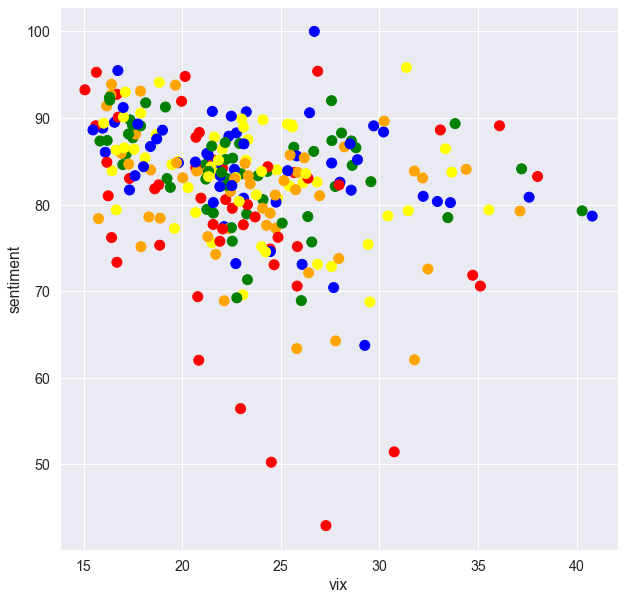

In [128]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'


# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
years = df_part3['year'].unique()

colors = dict(zip(df_part3.day.unique(), ['orange', 'yellow', 'green', 'blue', 'red']))
labels=['orange', 'yellow', 'green', 'blue', 'red']

df_part3.plot(figsize=(10, 10), x="vix", y="sentiment", kind="scatter", color=df_part3.day.map(lambda x: colors[x]), s=100)

Automatically created module for IPython interactive environment
Coefficients: 
 [938.23786125]
Mean squared error: 2548.07
Coefficient of determination: 0.47


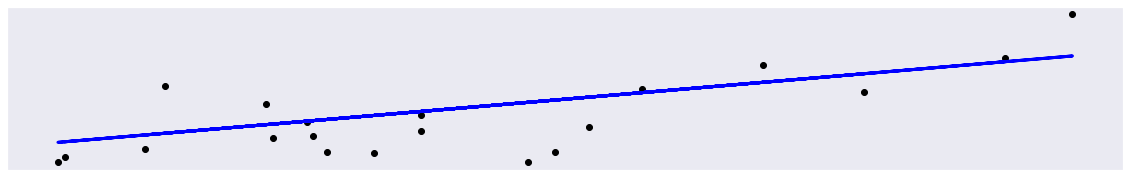

In [142]:
print(__doc__)


# Code source: Jaques Grobler
# License: BSD 3 clause


import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score

# Load the diabetes dataset
diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)

# Use only one feature
diabetes_X = diabetes_X[:, np.newaxis, 2]

# Split the data into training/testing sets
diabetes_X_train = diabetes_X[:-20]
diabetes_X_test = diabetes_X[-20:]

# Split the targets into training/testing sets
diabetes_y_train = diabetes_y[:-20]
diabetes_y_test = diabetes_y[-20:]

# Create linear regression object
regr = linear_model.LinearRegression()

# Train the model using the training sets
regr.fit(diabetes_X_train, diabetes_y_train)

# Make predictions using the testing set
diabetes_y_pred = regr.predict(diabetes_X_test)

# The coefficients
print('Coefficients: \n', regr.coef_)
# The mean squared error
print('Mean squared error: %.2f'
      % mean_squared_error(diabetes_y_test, diabetes_y_pred))
# The coefficient of determination: 1 is perfect prediction
print('Coefficient of determination: %.2f'
      % r2_score(diabetes_y_test, diabetes_y_pred))

# Plot outputs
plt.scatter(diabetes_X_test, diabetes_y_test,  color='black')
plt.plot(diabetes_X_test, diabetes_y_pred, color='blue', linewidth=3)

plt.xticks(())
plt.yticks(())
plt.rcParams["figure.figsize"] = (20,20)
# fig = matplotlib.pyplot.gcf()
# fig.set_size_inches(18.5, 10.5)
plt.show()

In [132]:
diabetes_y

array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
       128.,  52.,  37., 170., 170.,  61., 144.,  52., 128.,  71., 163.,
       150.,  97., 160., 178.,  48., 270., 202., 111.,  85.,  42., 170.,
       200., 252., 113., 143.,  51.,  52., 210.,  65., 141.,  55., 134.,
        42., 111.,  98., 164.,  48.,  96.,  90., 162., 150., 279.,  92.,
        83., 128., 102., 302., 198.,  95.,  53., 134., 144., 232.,  81.,
       104.,  59., 246., 297., 258., 229., 275., 281., 179., 200., 200.,
       173., 180.,  84., 121., 161.,  99., 109., 115., 268., 274., 158.,
       107.,  83., 103., 272.,  85., 280., 336., 281., 118., 317., 235.,
        60., 174., 259., 178., 128.,  96., 126., 28